# 2. Multi-antenna receivers and impairments

With an $N$-antenna server the receiver applies a unit-norm combiner $m$, and every device sees the
scalar effective channel $c_k = m^H h_k$. The combiner decides who is the weakest device and so
sets the MSE. AirCompKit ships four receivers:

| name | method |
|---|---|
| `eigen` | dominant eigenvector of the normalised channel covariance (cheap baseline) |
| `maxmin` | solver-free max-min-fair combiner (smoothed minimum, annealing, random restarts) |
| `sdr` | semidefinite relaxation solved through its dual in NumPy, plus Gaussian randomisation |
| `joint_mmse` | alternating LMMSE receive / per-device transmit design |

The SDR dual also gives a **certified bound**: no combiner can do better.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import aircompkit as ac

print("AirCompKit", ac.__version__)

AirCompKit 1.0.1


## Receivers against the SDR bound

Following Yang et al. (2020): $K=20$, unit power and noise, channel-inversion transmitters, complex
symbols. The MSE then equals $Q = \max_k \|m\|^2/|m^H h_k|^2$.

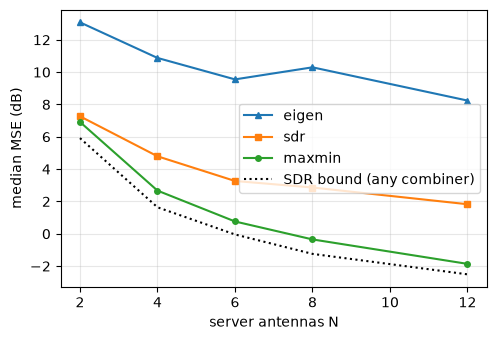

In [2]:
from aircompkit.core.rng import SeedTree
from aircompkit.receiver import sdr_solve

K, T = 20, 60
Ns = [2, 4, 6, 8, 12]
med = {r: [] for r in ("eigen", "sdr", "maxmin", "bound")}
for N in Ns:
    for r in ("eigen", "sdr", "maxmin"):
        sc = ac.Scenario(devices={"name": "fixed", "K": K}, channel={"name": "rayleigh", "n_rx": N},
                         power_control="channel_inversion", receiver=r, noise_var=1.0,
                         symbols="complex", seed=0)
        med[r].append(np.median(10 * np.log10(sc.run(trials=T, dim=0)["mse"])))
    h, _ = sc.channel.sample(SeedTree(0).generator("channel"), T, K)   # the same draws
    med["bound"].append(np.median(-10 * np.log10(sdr_solve(h)[2])))

fig, ax = plt.subplots(figsize=(5.5, 3.6))
for r, st in (("eigen", "^-"), ("sdr", "s-"), ("maxmin", "o-"), ("bound", "k:")):
    ax.plot(Ns, med[r], st, ms=4, label="SDR bound (any combiner)" if r == "bound" else r)
ax.set_xlabel("server antennas N"); ax.set_ylabel("median MSE (dB)"); ax.grid(alpha=0.3); ax.legend()
plt.show()

`maxmin` sits almost on the bound, while the cheap `eigen` combiner loses several dB.

## Imperfect CSI and phase errors

`impairments` adds a channel-estimation error ($\hat h = h + e$, $e\sim\mathcal{CN}(0,\varepsilon^2\beta_k I)$)
and a residual phase error at transmission. Both have their own random streams, so the channel
draws stay paired with the impairment-free run, and the curves below isolate the impairment.

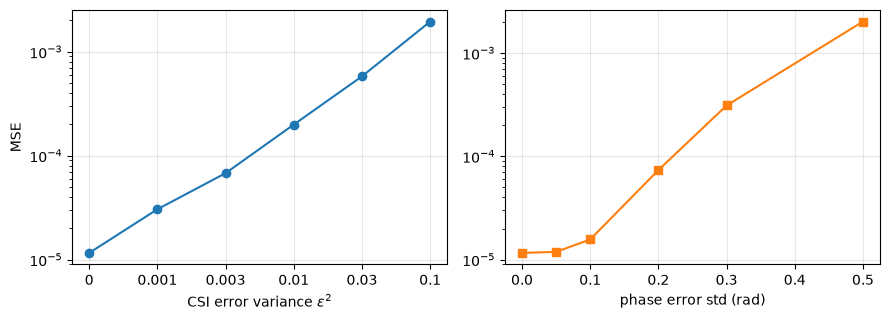

In [3]:
base = dict(devices={"name": "fixed", "K": 20, "p_max": 100.0},
            channel={"name": "rayleigh", "n_rx": 8}, power_control="optimal",
            receiver="maxmin", target="mean", noise_var=1.0, seed=0)
eps2 = [0, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1]
phase = [0, 0.05, 0.1, 0.2, 0.3, 0.5]
m_csi = [ac.Scenario(**base, impairments={"csi_error": e}).run(trials=200, dim=0)["mse"].mean() for e in eps2]
m_ph = [ac.Scenario(**base, impairments={"phase_error_std": s}).run(trials=200, dim=0)["mse"].mean() for s in phase]

fig, (a, b) = plt.subplots(1, 2, figsize=(9, 3.3))
a.semilogy(range(len(eps2)), m_csi, "o-"); a.set_xticks(range(len(eps2)), [str(e) for e in eps2])
a.set_xlabel(r"CSI error variance $\varepsilon^2$"); a.set_ylabel("MSE"); a.grid(alpha=0.3)
b.semilogy(phase, m_ph, "s-", color="tab:orange"); b.set_xlabel("phase error std (rad)"); b.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## Rician fading and spatial correlation

A line-of-sight component (`rician`, `k_factor`) and correlated antennas (`corr`, exponential
model) change how well the combiner can separate devices:

In [4]:
for ch in ({"name": "rayleigh", "n_rx": 8}, {"name": "rayleigh", "n_rx": 8, "corr": 0.9},
           {"name": "rician", "n_rx": 8, "k_factor": 10.0}):
    mse = ac.Scenario(**{**base, "channel": ch}).run(trials=200, dim=0)["mse"].mean()
    print(f"{str(ch):55s} MSE {mse:.4g}")

{'name': 'rayleigh', 'n_rx': 8}                         MSE 1.16e-05


{'name': 'rayleigh', 'n_rx': 8, 'corr': 0.9}            MSE 1.485e-05


{'name': 'rician', 'n_rx': 8, 'k_factor': 10.0}         MSE 9.369e-06


Next: [over-the-air federated learning](03_over_the_air_fl.ipynb).